# Atera 空间可视化 — 圆形 ROI 与物理比例尺

本 notebook 用一份 Atera 官方 Zarr bundle 走完一条完整的出图链路：

1. **读取**：按 µm 区域裁剪，只给选中的细胞构建多边形
2. **整体图**：全视野 + 自动比例尺
3. **选 ROI**：在图上点一个圆心，按**物理半径**（µm）选取细胞
4. **ROI 图**：同样带比例尺，长度随视野自动变短
5. **组合图**：整体图上圈出 ROI，两panel 都带比例尺

关键在于**比例尺的长度是从数据推出来的**：同一份数据，整体图给 100 µm，300 µm 的 ROI 给 50 µm，60 µm 的视野给 10 µm。写死一个像素长度做不到这件事，而且会悄悄错 3 倍（Visium HD 的磅值是像素）。

需要 `trackcell >= 0.4.5`（`tl.cells_in_radius` 与 `pl.mark_circle` 从这一版开始提供）。数据路径用环境变量 `ATERA_DATA` 指定，指向含 `kidney_official/` 的目录。

In [1]:
import os
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*have no stored geometry.*")

import numpy as np
import matplotlib.pyplot as plt

import trackcell as tcl

DATA_DIR = Path(os.environ.get("ATERA_DATA", ".")).expanduser()
ROI = DATA_DIR / "kidney_official"      # 一个 ROI = 一个 bundle

plt.rcParams["figure.dpi"] = 110
print("trackcell :", tcl.__version__)
print("ROI bundle :", ROI.name, "| exists:", ROI.exists())

trackcell : 0.4.5
ROI bundle : kidney_official | exists: True


## 1. 读取：按 µm 区域裁剪

`read_atera(region=(xmin, ymin, xmax, ymax))` 的单位是 **µm**。细胞先按 centroid
过滤，再只为选中的细胞构建多边形 —— 所以读取成本跟 ROI 走，而不是跟整张切片走。

这里取 1 mm × 1 mm 的一块作为「整体图」的范围。

In [2]:
adata = tcl.io.read_atera(
    ROI,
    region=(4000, 2000, 5000, 3000),   # xmin, ymin, xmax, ymax (µm)
    build_polygons=True,
    include_nucleus=False,             # 本例不用核多边形，省一半构建时间
    verbose=False,
)
adata

AnnData object with n_obs × n_vars = 6674 × 24674
    obs: 'barcode', 'cell_id', 'filtered', 'leiden_res_1.0', 'centroid_column', 'centroid_row', 'cell_area', 'nucleus_area', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'total_counts', 'azimuth_broad', 'azimuth_coarse', 'azimuth_fine', 'azimuth_score', 'azimuth_full_hierarchy', 'cell_prefix', 'dataset_suffix'
    var: 'feature_name', 'filtered', 'highly_variable', 'feature_id', 'feature_type', 'genome', 'gene_ids', 'feature_types', 'is_gene_expression'
    uns: 'experiment', 'atera', 'spatial', 'cell_boundaries'
    obsm: 'X_pca', 'X_umap', 'spatial'

### 坐位单位决定比例尺对不对

Atera 的 `obsm['spatial']` **已经是 µm**，`uns['atera']['coord_unit']` 也写了 `'um'`，
所以比例尺的换算因子是 `1.0`。`metadata['pixel_size']` 只用于形态学图像像素，
**绝不能**乘到 centroid 上。

Visium HD 正相反：`obsm['spatial']` 是全分辨率像素，必须乘
`scalefactors['microns_per_pixel']`。`resolve_microns_per_unit()` 会自己判断：

| 数据 | 坐标单位 | 换算因子 |
|---|---|---|
| Xenium / Atera / MERSCOPE | µm | 1.0 |
| Visium / Visium HD | 全分辨率像素 | `microns_per_pixel`（如 0.32512） |

In [3]:
mpp, unit = tcl.pl.resolve_microns_per_unit(adata, library_id="kidney")
span = np.ptp(adata.obsm["spatial"], axis=0)

print(f"microns per data unit : {mpp}  (unit family: {unit})")
print(f"视野跨度              : {span[0]:.0f} × {span[1]:.0f} µm")
print(f"自动比例尺长度        : {tcl.pl.nice_scale_length(span[0] * 0.18):.0f} µm"
      "   ← 可见宽度的 18%，取 1/2/5×10ⁿ")

microns per data unit : 1.0  (unit family: um)
视野跨度              : 1000 × 999 µm
自动比例尺长度        : 100 µm   ← 可见宽度的 18%，取 1/2/5×10ⁿ


`azimuth_coarse` 有 50 个类别，直接上图例会挤满画布。这里把它压成 10 个主要类别 +
`Other`，只为出图好看，与比例尺无关。

In [4]:
import pandas as pd

ABBREV = {
    "Renal epithelial cell - proximal tubules": "PT",
    "Renal epithelial cell - Loop of Henle": "Loop of Henle",
    "Renal epithelial cell - distal tubules": "DT",
    "Endothelial cell": "Endo",
    "Macrophage": "Macrophage",
    "Pericyte": "Pericyte",
    "Fibroblast": "Fibroblast",
    "Vascular smooth muscle cell": "VSMC",
    "T cell": "T cell",
    "B cell": "B cell",
}
adata.obs["celltype"] = pd.Categorical(
    adata.obs["azimuth_coarse"].astype(str).map(ABBREV).fillna("Other")
)
adata.obs["celltype"].value_counts()

celltype
Other            1593
PT               1424
Loop of Henle     789
Macrophage        591
Endo              590
DT                571
Pericyte          281
T cell            276
Fibroblast        262
B cell            151
VSMC              146
Name: count, dtype: int64

## 2. 整体图 + 自动比例尺

`scalebar=True` 就够了：长度 = 可见宽度的约 18%，四舍五入到 1/2/5×10ⁿ µm。
所以 1000 µm 的视野得到 100 µm 的比例尺，而不是图上随便一根线。

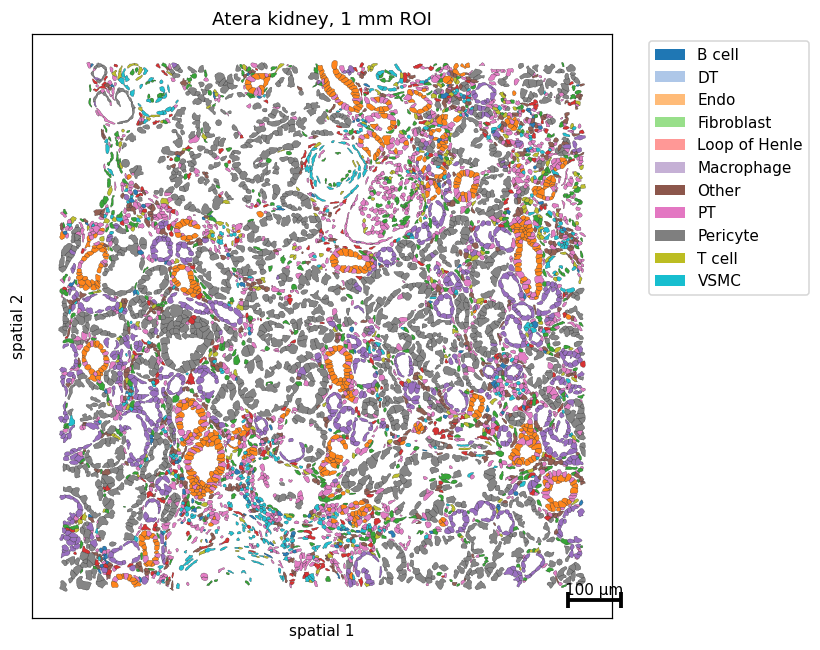

In [5]:
fig, ax = plt.subplots(figsize=(7.5, 7.5))
tcl.pl.spatial_cell(
    adata,
    color="celltype",
    edges_width=0.15,
    alpha=0.95,
    scalebar=True,                 # ← 就这一个参数
    legend=True,
    show=False,
    ax=ax,
)
ax.set_title("Atera kidney, 1 mm ROI", fontsize=12)
plt.tight_layout()
plt.show()

## 3. 选圆心：点一下，或者直接给坐标

交互式（需 `%matplotlib widget`，仅在 Jupyter 里有意义，故此处不执行）：

```python
%matplotlib widget
ax = tcl.pl.spatial_cell(adata, color="celltype", scalebar=True, show=False)
center = plt.ginput(1)[0]      # 点一下，返回数据坐标
print(center)                  # 例如 (4470.2, 2620.9) —— Atera 下就是 µm
```

`ginput` 返回的就是 `obsm['spatial']` 的坐标系，所以可以直接喂给下一步。
下面为了可复现，直接写一个坐标：

In [6]:
center = (4470.0, 2620.0)          # (x, y) in µm
radius = 150.0                     # 半径，µm

print(f"center = {center} µm, radius = {radius} µm")

center = (4470.0, 2620.0) µm, radius = 150.0 µm


## 4. 按物理半径选细胞

`tcl.tl.cells_in_radius(adata, center, radius)`:

* `center` 用 `obsm['spatial']` 的坐标（即图上的数）
* `radius` 默认是 **µm**；像素坐标的数据会自动乘 `microns_per_pixel`
* 返回与 `obs_names` 对齐的布尔掩码，可直接 `adata[mask].copy()`

`return_distances=True` 还能拿到每个细胞到圆心的物理距离。

In [7]:
mask, dist_um = tcl.tl.cells_in_radius(
    adata, center, radius, return_distances=True
)
roi = adata[mask].copy()

area_um2 = np.pi * radius**2
print(f"选中细胞 : {mask.sum():,} / {adata.n_obs:,}")
print(f"圆面积   : {area_um2:,.0f} µm²")
print(f"细胞密度 : {mask.sum() / area_um2 * 1e4:,.1f} cells / 100 µm²")
print(f"距离范围 : {dist_um[mask].min():.1f} – {dist_um[mask].max():.1f} µm")

选中细胞 : 415 / 6,674
圆面积   : 70,686 µm²
细胞密度 : 58.7 cells / 100 µm²
距离范围 : 9.1 – 149.8 µm


## 5. ROI 图 + 比例尺

同一个函数，换成子集对象即可。注意比例尺**自动变短了**：
视野从 1000 µm 缩到 330 µm，比例尺就从 100 µm 变成 50 µm。

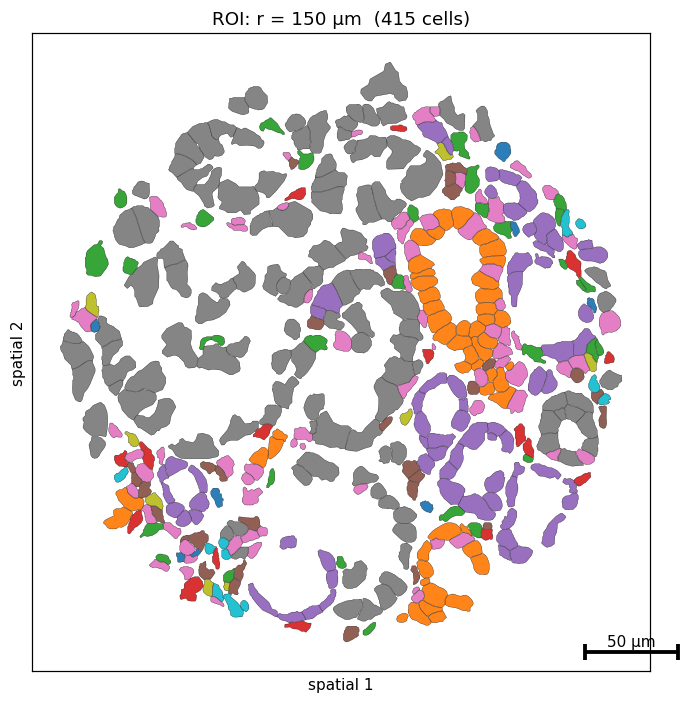

In [8]:
fig, ax = plt.subplots(figsize=(6.5, 6.5))
tcl.pl.spatial_cell(
    roi,
    color="celltype",
    edges_width=0.2,
    alpha=0.95,
    scalebar=True,
    legend=False,
    show=False,
    ax=ax,
)
ax.set_title(f"ROI: r = {radius:.0f} µm  ({roi.n_obs:,} cells)", fontsize=12)
plt.tight_layout()
plt.show()

## 6. 同一圆心，不同物理半径

三个半径 75 / 150 / 300 µm，每个 panel 各自自动取比例尺。
视野越大，比例尺的物理长度越大 —— 这正是「不同画图范围物理比例尺不同」的意思，
而读者看到的永远是「这根线的真实长度」。

In [9]:
print("半径 → 视野 → 自动比例尺")
rows = []
for r in (75, 150, 300):
    sub = adata[tcl.tl.cells_in_radius(adata, center, r)].copy()
    c = np.asarray(sub.obsm["spatial"])
    span_r = 1.1 * np.ptp(c[:, 0])           # spatial_cell 每侧留 5% padding
    rows.append((r, span_r, tcl.pl.nice_scale_length(span_r * 0.18), sub.n_obs))
    print(f"{r:>4.0f} µm → {span_r:>5.0f} µm → {rows[-1][2]:>5.0f} µm → "
          f"{sub.n_obs:>6,} cells")

半径 → 视野 → 自动比例尺
  75 µm →   154 µm →    20 µm →     91 cells
 150 µm →   321 µm →    50 µm →    415 cells
 300 µm →   654 µm →   100 µm →  1,897 cells


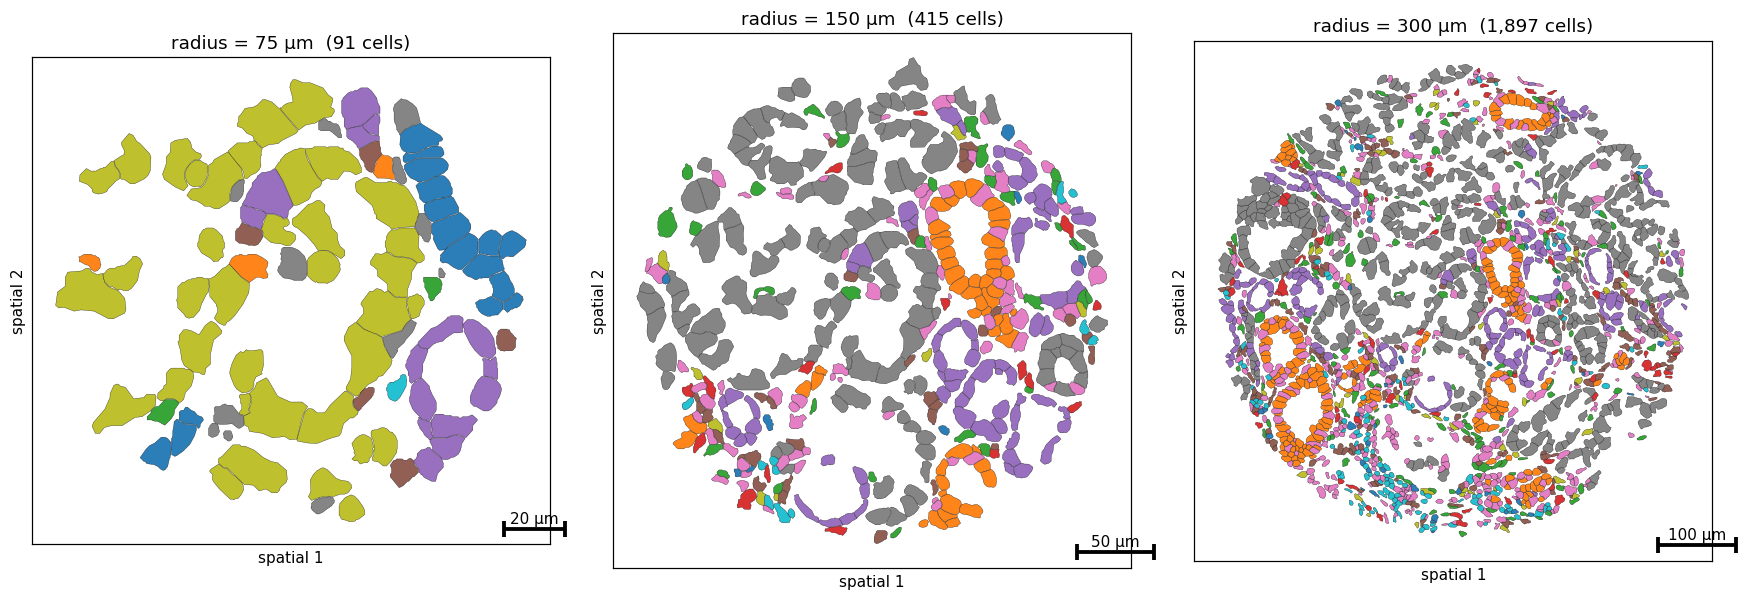

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5.6))
for panel, (r, _, _, _) in zip(axes, rows):
    sub = adata[tcl.tl.cells_in_radius(adata, center, r)].copy()
    tcl.pl.spatial_cell(
        sub,
        color="celltype",
        edges_width=0.2,
        alpha=0.95,
        scalebar=True,
        legend=False,
        show=False,
        ax=panel,
    )
    panel.set_title(f"radius = {r:.0f} µm  ({sub.n_obs:,} cells)", fontsize=12)
fig.tight_layout()
plt.show()

## 7. 组合图：整体图上圈出 ROI

最后这张就是投稿用的那种图 —— 左panel 整体（带比例尺 + 圆圈标注），
右panel 放大（带比例尺 + 一行说明）。两panel 的比例尺长度不同，这是对的。

`mark_circle()` 与 `cells_in_radius()` 共用同一套单位语义：
`radius_unit="um"` + `adata`，因此画出来的圈和选出来的细胞严格一致。
右panel 顺带演示比例尺的样式可调（位置、线宽、字号、背景框）。

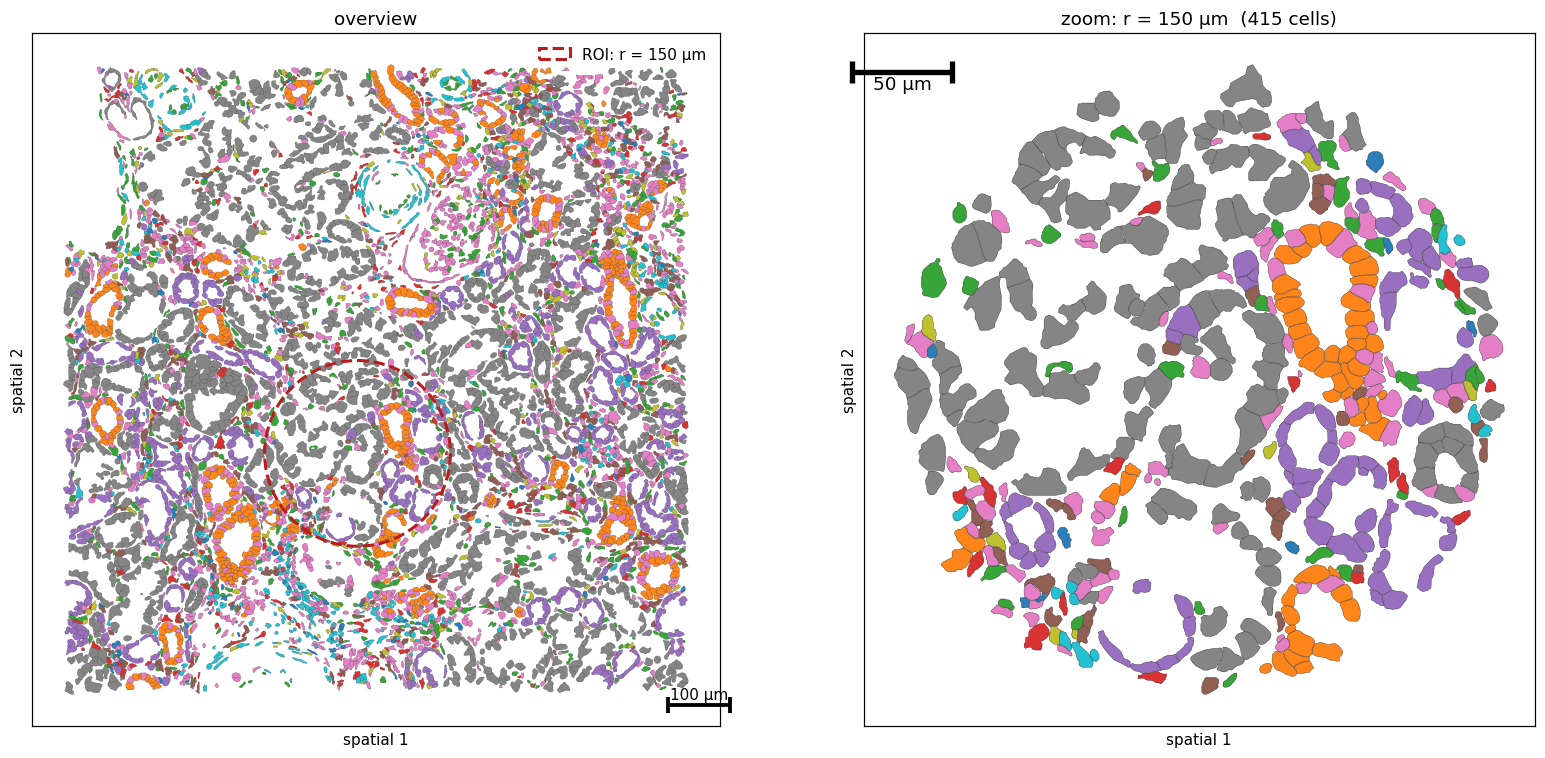

In [11]:
fig, (ax_l, ax_r) = plt.subplots(1, 2, figsize=(15, 7))

# 左：整体
tcl.pl.spatial_cell(
    adata, color="celltype", edges_width=0.12, alpha=0.95,
    scalebar=True, legend=False, show=False, ax=ax_l,
)
tcl.pl.mark_circle(
    ax_l, center, radius,
    radius_unit="um", adata=adata,
    edges_color="#b91c1c", edges_width=2.0, linestyle="--",
    label=f"ROI: r = {radius:.0f} µm", show=False,
)
ax_l.legend(loc="upper right", frameon=False, fontsize=10)
ax_l.set_title("overview", fontsize=12)

# 右：放大，比例尺换样式
tcl.pl.spatial_cell(
    roi, color="celltype", edges_width=0.2, alpha=0.95,
    scalebar=dict(
        loc="upper left",          # 位置可调
        color="black", linewidth=3.5, fontsize=12,
        label_position="below",    # 文字在线的哪一侧
        offset=(12, -12),          # 额外位移，单位：点
    ),
    legend=False, show=False, ax=ax_r,
)
ax_r.set_title(f"zoom: r = {radius:.0f} µm  ({roi.n_obs:,} cells)", fontsize=12)

fig.tight_layout()
plt.show()

## 8. 比例尺参数速查

| 参数 | 说明 |
|---|---|
| `scalebar=True` | 自动长度：可见宽度的 ~18%，取 1/2/5×10ⁿ µm |
| `scalebar="50um"` / `50` | 定长；也接受 `"100 µm"`、`"20px"` |
| `scalebar=dict(...)` | 下面是可调项 |
| `length` | `"auto"` / 数值 / 带单位字符串 |
| `loc` | `lower right`（默认）、`upper left`、`center right` … |
| `pad` / `offset` | 轴内缩（轴分数）/ 额外位移（点） |
| `frac` | 自动长度占可见宽度的比例 |
| `color` / `linewidth` / `fontsize` / `alpha` | 线色、线宽、字号、透明度 |
| `caps` / `cap_size` | 端点短竖线（`|——|`）及其高度 |
| `label` / `label_position` | 自定义文字 / `auto`、`above`、`below`、`none` |
| `frame` / `frame_color` / `frame_alpha` | H&E 背景上可读性用的衬底框 |
| `microns_per_unit` | 覆盖单位推断（无 scalefactors 的像素坐标） |

任何 matplotlib 坐标轴都能单独加比例尺：

```python
info = tcl.pl.add_scale_bar(ax, adata, length="100um", loc="lower left")
# {'length': 100.0, 'label': '100 µm', 'axes_fraction': 0.025, ...}
```

比例尺短于可见宽度 2% 时会告警：那是物理上正确、但肉眼读不出来的一根线，
应该换更长的 `length` 或调大 `frac`。

## 小结

* Atera 的坐标已是 µm，比例尺换算因子为 1.0；Visium HD 是像素，会自动乘 `microns_per_pixel`
* `scalebar=True` 让比例尺长度跟视野走，整体图 / ROI 图自然得到不同但都正确的长度
* 圆形 ROI = 圆心（点）+ 物理半径（µm）：`tl.cells_in_radius()`
* `pl.mark_circle()` 在整体图上标出同一个圆，与选中的细胞严格一致

延伸阅读：

* :doc:`../usage/atera` — Atera 读取、多边形、单分子点云、QC
* :doc:`../usage/visualization` — 双色叠加、多基因 blend、交互式 ROI、比例尺